# Inestabilidad de Rayleigh - Taylor

## Objetivo
En este proyecto analizaremos el comportamiento de la ecuacion de inestabilidad de Rayleigh - Taylor con uno de los ejemplos incluidos en el codigo de magnetohidrodinamica del software libre PLUTO, adicionalmente se intentara replicar el comportamiento de estas ecuaciones en un codigo propio construido en python

## Marco Teórico: Inestabilidad de Rayleigh-Taylor en Magnetohidrodinámica (MHD)

Este proyecto modela la inestabilidad de Rayleigh-Taylor (RT) para fluidos incompresibles en el régimen de MHD ideal (conductividad eléctrica infinita y sin viscosidad). 

### 1. Conservación de la Masa (Incompresibilidad)
Para un fluido donde la densidad de las parcelas no cambia por compresión, la ecuación de continuidad se reduce a la condición de divergencia nula:
$$ \nabla \cdot \vec{v} = 0 $$
* En lugar de resolver las velocidades $u$ y $v$ por separado (lo cual suele violar esta regla numéricamente), introducimos la **Función de Corriente ($\psi$)**. Al definir $u = \partial\psi/\partial y$ y $v = -\partial\psi/\partial x$, garantizamos matemáticamente que el fluido jamás se comprima.

### 2. Conservación del Momento (Ecuación de Navier-Stokes)
La Segunda Ley de Newton aplicada a fluidos nos dice cómo cambian las velocidades debido a las fuerzas externas:
$$ \rho \left( \frac{\partial \vec{v}}{\partial t} + \vec{v} \cdot \nabla \vec{v} \right) = -\nabla p + \rho \vec{g} + \vec{J} \times \vec{B} $$
*(El lado derecho representa: Gradiente de Presión + Gravedad + Fuerza de Lorentz).*

* Resolver la presión dinámicamente es costoso. Para esquivarlo, aplicamos el operador *rotacional* ($\nabla \times$) a toda la ecuación. El rotacional del gradiente de presión es cero ($\nabla \times \nabla p = 0$), eliminando la presión. Así obtenemos la **Ecuación de Vorticidad ($\omega$)**:
$$ \frac{\partial \omega}{\partial t} + \vec{v} \cdot \nabla \omega = -\frac{g}{\rho_0} \frac{\partial \rho}{\partial x} + \frac{1}{\rho_0} \nabla \times (\vec{J} \times \vec{B}) $$
El término $-(g/\rho_0) \partial\rho/\partial x$ (término baroclínico) es el motor de la inestabilidad: siempre que haya un gradiente de densidad horizontal, se generará rotación ($\omega$) que impulsará el "hongo".

### 3. Transporte de la Densidad
Como las parcelas no se comprimen, la densidad simplemente "viaja" con el flujo. Esto se modela con la ecuación de advección pura:
$$ \frac{\partial \rho}{\partial t} + \vec{v} \cdot \nabla \rho = 0 $$
* Esta ecuación dirige el movimiento macroscópico de las fases. La resolvemos utilizando el esquema de diferencias finitas *Upwind* (`advec_rho`) para evitar inestabilidades numéricas durante el transporte.

### 4. Ecuación de Inducción Magnética (Leyes de Maxwell)
Las ecuaciones de Faraday y la Ley de Ohm ideal dictan cómo el campo magnético interactúa con el fluido:
$$ \frac{\partial \vec{B}}{\partial t} = \nabla \times (\vec{v} \times \vec{B}) + \eta_{res} \nabla^2 \vec{B} $$
* En un espacio 2D, los vectores $\vec{B}$ están en el plano $xy$. Esto permite usar el **Potencial Vectorial Magnético ($A$)** (actuando en el eje $z$). La ecuación se reduce a:
$$ \frac{\partial A}{\partial t} + \vec{v} \cdot \nabla A = \eta_{res} \nabla^2 A $$
Las líneas de campo magnético "fluyen" con el fluido (advección de $A$) pero pueden difuminarse si hay resistividad eléctrica.

---

## Análisis de Estabilidad Lineal (Teoría de Perturbaciones)

### 5. Configuración del Estado Base
Consideramos un sistema de dos fluidos separados por una interfaz plana en $z = 0$, sometidos a una gravedad uniforme $\mathbf{g} = -g \hat{z}$ y un campo magnético horizontal constante $\mathbf{B}_0 = B_0 \hat{x}$.

* **Región Superior ($z > 0$):** Fluido pesado con densidad $\rho_1$.
* **Región Inferior ($z < 0$):** Fluido ligero con densidad $\rho_2$ (donde $\rho_1 > \rho_2$).

En equilibrio estático ($\mathbf{v}_0 = 0$), el balance hidrostático es:
$$ \frac{d}{dz} \left( p_0 + \frac{B_0^2}{2\mu_0} \right) = -\rho_0 g $$

### 6. Condiciones de Frontera y de Interfaz
Para resolver el sistema diferencial linealizado, se aplican condiciones en los límites del dominio y en la superficie de separación:

**Condiciones de Contorno Espaciales (Límites del Dominio)**
* **Direcciones Horizontales ($x, y$):** Se asumen **condiciones periódicas**. Esto permite modelar el crecimiento de las ondas sin que interfieran efectos de pared.
  $$ f(x, y, z, t) = f(x + L_x, y + L_y, z, t) $$
* **Dirección Vertical ($z$):**
  * *Modelo Analítico (Dominio Infinito):* Las perturbaciones decaen a cero lejos de la interfaz ($\hat{v}_z \to 0$ cuando $z \to \pm \infty$).
  * *Modelo Computacional (Dominio Finito):* En simuladores como PLUTO, se emplean **condiciones de pared reflectante** (slip boundaries) obligando a que la velocidad normal se anule ($v_z = 0$ en los bordes).

**Condiciones de Salto en la Interfaz ($z = 0$)**
1. **Condición Cinemática:** La componente vertical de la velocidad es continua para que los fluidos no se separen:
   $$ [\hat{v}_z] = 0 \implies \hat{v}_{z1} (z=0^+) = \hat{v}_{z2} (z=0^-) $$
2. **Condición Dinámica:** La presión total (térmica + magnética) equilibra la deformación superficial:
   $$ \left[ \Pi_1 \right] = \left[ p_1 + \frac{\mathbf{B}_0 \cdot \mathbf{B}_1}{\mu_0} \right] \quad \text{es continua a través del límite deformado.} $$

### 7. Relación de Dispersión
Aplicando teoría de perturbaciones lineales ($f_1 = \hat{f}_1(z) e^{\gamma t + i(k_x x + k_y y)}$) y resolviendo las condiciones de contorno, se obtiene la relación de dispersión para la inestabilidad:

$$ \gamma^2 = g k \left( \frac{\rho_1 - \rho_2}{\rho_1 + \rho_2} \right) - \frac{2(\mathbf{k} \cdot \mathbf{B}_0)^2}{\mu_0 (\rho_1 + \rho_2)} $$

Donde:
* $\gamma$: Tasa de crecimiento de la inestabilidad.
* $\mathbf{k}$: Vector de onda de la perturbación horizontal ($k = |\mathbf{k}|$).

### 8. Análisis Físico de la Inestabilidad
La ecuación de dispersión revela dos mecanismos opuestos:

1. **Término Gravitatorio (Desestabilizador):** El término proporcional a $gk$ contiene el número de Atwood. Al ser $\rho_1 > \rho_2$, este término es positivo e impulsa el crecimiento de la inestabilidad.
2. **Término Magnético (Estabilizador):** El término proporcional a $(\mathbf{k} \cdot \mathbf{B}_0)^2$ es negativo. Representa la **tensión magnética**, actuando como fuerza restauradora cuando la perturbación dobla las líneas de campo.

**Condición de Estabilidad:** 
Las perturbaciones con longitudes de onda muy cortas (alto $k$) son suprimidas por completo por el campo magnético. El sistema es estable ($\gamma^2 < 0$) para números de onda que superan el valor crítico:
$$ k_c = \frac{g \mu_0 (\rho_1 - \rho_2)}{2 B_0^2 \cos^2\theta} $$
*(Donde $\theta$ es el ángulo entre el vector de onda $\mathbf{k}$ y el campo magnético $\mathbf{B}_0$).*

### Avances Recientes en el Modelado de la Inestabilidad de Rayleigh-Taylor (RTI)

El estudio de la inestabilidad de Rayleigh-Taylor (RTI) en plasmas astrofísicos, como las prominencias solares, ha evolucionado al superar las limitaciones de las aproximaciones lineales clásicas. Actualmente, la investigación se centra en la dinámica no lineal y los efectos del campo magnético sobre el plasma. Los procesos y avances más destacados incluyen:

*   **Caracterización de la turbulencia mediante simulaciones MHD:** El uso de códigos de alta resolución ha permitido modelar la evolución no lineal del plasma hasta un estado completamente turbulento. Estos avances han confirmado que el campo magnético genera una turbulencia anisotrópica y han revelado un comportamiento multifractal e intermitente en las escalas más pequeñas.
*   **Modelado analítico del régimen no lineal:** La extensión de los modelos de potencial a las ecuaciones magnetohidrodinámicas ha proporcionado soluciones analíticas exactas para el crecimiento de la inestabilidad.
*   **Aceleración inducida por campos magnéticos:** A diferencia de la fase lineal (donde el campo inhibe el crecimiento), los modelos teóricos y las simulaciones (DNS) han demostrado que en el régimen no lineal el campo magnético acelera la inestabilidad, permitiendo que las burbujas y espigas superen la velocidad de Alfvén del fluido pesado.
*   **Inferencia magnética observacional:** Las soluciones no lineales desarrolladas actúan como un método inverso, proporcionando una herramienta matemática para deducir la magnitud y orientación de los campos magnéticos en objetos astrofísicos a partir de la velocidad observada en las estructuras del plasma.

## Implementacion PLUTO

El código de PLUTO implementa las siguientes condiciones iniciales analíticas para resolver el problema:

$$ \rho(y) = \begin{cases} 1 & \text{para} \quad y \le 0 \\ \eta & \text{para} \quad y > 0 \end{cases}, \qquad p = p_0 + \rho y g $$

La densidad del fluido inferior ($y \le 0$) se normaliza a un valor de 1, mientras que el fluido en la parte superior ($y > 0$) tiene una densidad definida por el parámetro $\eta$. La gravedad ($g$) es constante y apunta hacia la dirección $y$ negativa, y el valor de la presión en la interfaz ($p_0$) se selecciona de manera que la velocidad del sonido en el fluido ligero sea exactamente 1. Además, la extensión horizontal del dominio computacional define la unidad de longitud con $L_x=1$.

Para los escenarios magnetizados, se aplica un campo magnético puramente horizontal definido por la ecuación $\mathbf{B} = \chi B_c \hat{\mathbf{i}}$. El valor $B_c = \sqrt{(\eta - 1.0)\vert{}g\vert{}}$ representa el campo magnético crítico a partir del cual se suprimen las perturbaciones que son paralelas al campo magnético. La variable $\chi$ es un factor proporcionado directamente por el usuario.

Una de las diferencias más profundas entre nuestro modelo numérico y PLUTO —y la principal fuente física de las discrepancias ($L_1$ y $L_2$) que cuantificamos— es el tratamiento matemático de la compresibilidad del fluido.

#### El Enfoque de PLUTO (Fluidos Compresibles)
PLUTO está diseñado como un código astrofísico que resuelve las ecuaciones completas de la MHD compresible (conservación de masa, momento y energía).
* **Física termodinámica:** En PLUTO, el volumen de una "parcela" de fluido cambia si se le somete a presión. La densidad ($\rho$) y la presión ($p$) son variables termodinámicas dinámicas e independientes, conectadas íntimamente por una Ecuación de Estado (EOS).
* **Ondas acústicas:** Al permitir que el fluido se comprima, el modelo de PLUTO simula naturalmente la propagación de ondas de sonido. Esto lo hace muy preciso, pero obliga computacionalmente a usar un paso de tiempo ($\Delta t$) microscópico, ya que el esquema numérico debe "atrapar" no solo la velocidad a la que cae el fluido, sino la velocidad a la que viaja el sonido a través de él.

#### Nuestro Enfoque en Python (Fluidos Incompresibles)
Para simplificar la carga computacional y centrar el estudio únicamente en el crecimiento estructural de la inestabilidad, nuestro código asume un fluido totalmente incompresible matemáticamente, imponiendo la condición de divergencia nula: $\nabla \cdot \vec{v} = 0$.
* **Advección pura:** En nuestra simulación, las parcelas de fluido no pueden comprimirse ni expandirse. La densidad de un punto cambia exclusivamente porque un fluido diferente ha llegado a esa posición (transporte o advección de $\rho$), no porque se haya "aplastado".
* **El nuevo rol de la Presión:** Como evidenciamos en el post-procesamiento del código, la presión ya no es una variable termodinámica dependiente de la temperatura o la energía. Se convierte en una **fuerza de restricción mecánica**. Resolvemos la ecuación de Poisson para la presión dinámica con el único propósito de obligar al campo de velocidades a mantenerse incompresible en el siguiente instante.
* **Filtrado Acústico:** Al usar la formulación de Función de Corriente y Vorticidad ($\psi - \omega$), filtramos artificial e intencionalmente todas las ondas de sonido del sistema. 



## Resultados del codigo PLUTO

<table>
  <tr>
    <td align="center"><img src="Densidad.png" alt="Densidad" width="400"/><br/><b>Densidad (rho)</b></td>
    <td align="center"><img src="Bx.png" alt="Bx" width="400"/><br/><b>Campo Magnético (Bx)</b></td>
    <td align="center"><img src="By.png" alt="By" width="400"/><br/><b>Campo Magnético (By)</b></td>
  </tr>
  <tr>
    <td align="center"><img src="prs.png" alt="Presión" width="400"/><br/><b>Presión (prs)</b></td>
    <td align="center"><img src="Velx.png" alt="Velocidad vx" width="400"/><br/><b>Velocidad Horizontal (vx)</b></td>
    <td align="center"><img src="Vely.png" alt="Velocidad vy" width="400"/><br/><b>Velocidad Vertical (vy)</b></td>
  </tr>
</table>

## Reproduccion en python

### Adaptación Numérica en Python (Benchmark)
Para validar nuestro código frente a PLUTO, replicamos estas condiciones físicas con tres adaptaciones necesarias para la estabilidad de nuestro esquema numérico:

#### 1. Suavizado Numérico de la Interfaz
Mientras que la ecuación analítica define un salto brusco (función escalón) en la densidad $\rho(y)$, un salto infinito colapsaría las derivadas de nuestro esquema de diferencias finitas en el primer paso de tiempo. En el código, la transición en $y=0$ se suaviza sutilmente a lo largo de un par de celdas para mantener la estabilidad del esquema Upwind sin alterar la física global.

#### 2. Perturbación de Velocidad ("Semilla")
El estado base descrito por las ecuaciones de presión y densidad está en perfecto equilibrio hidrostático. Para romper este equilibrio estancado y permitir que la gravedad actúe sobre la diferencia de densidades, inyectamos una pequeña perturbación sinusoidal en la velocidad vertical ($v$) a lo largo de la interfaz. Esto actúa como "semilla" para que se formen los característicos hongos invertidos.

#### 3. Redimensionamiento de la Malla Espacial ($128 \times 256$)
Aunque mantenemos la física y las dimensiones geométricas ($L_x = 1$), ajustamos la resolución de la cuadrícula a $128 \times 256$ celdas. Esto nos brinda dos beneficios:
* **Físico:** Mayor espacio vertical para que las plumas densas caigan libremente antes de chocar con las fronteras sólidas de Dirichlet en el fondo.
* **Analítico:** Permite un mapeo espacial 1:1 exacto con los datos binarios exportados de PLUTO (`data.0001.dbl`), lo cual es indispensable para el cálculo directo de las normas de error $L_1$ y $L_2$ celda por celda.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#Parámetros físicos y de la malla
Nx, Ny = 128, 256
Lx, Ly = 1.0, 2.0
dx = Lx / Nx
dy = Ly / Ny
g = 0.1 # PLUTO usa magnitud 0.1
rho_0 = 1.0
rho_sup = 2.0
rho_inf = 1.0
chi = 0.2
t_final = 15.0
dt = 0.005       # Paso de tiempo pequeño para cumplir CFL
pasos = int(t_final / dt)

#Inicialización de campos
omega = np.zeros((Ny, Nx))
psi   = np.zeros((Ny, Nx))
rho   = np.zeros((Ny, Nx))

# Nuevos parámetros MHD
eta_res = 0.0     # Difusividad magnética (resistividad)
B0 = chi * np.sqrt(((rho_sup - rho_inf) * np.abs(g)) / (4 * np.pi))        # Fuerza del campo magnético inicial horizontal

amplitud_perturbacion = 0.01 / dy
#Condición inicial: Perturbación en la interfaz
for j in range(Ny):
    for i in range(Nx):
        y_interface = (Ny / 2) + 1.5 * np.cos(2 * np.pi * i / Nx)
        rho[j, i] = rho_sup if j > y_interface else rho_inf  # Pesado arriba, ligero abajo (para cumplir con la misma condicion incial de PLUTO el superior es el doble de mayor al inferior)

# Inicialización de campos magnéticos
A = np.zeros((Ny, Nx))
# Un campo B_x uniforme significa que A = B0 * y
for j in range(Ny):
    y_fisico = -1.0 + (j * dy)
    A[j, :] = B0 * y_fisico


## Implementacion T.STEP

El siguiente bloque de código representa el núcleo computacional de nuestra simulación magnetohidrodinámica (MHD). En cada iteración (paso de tiempo), el código resuelve las ecuaciones diferenciales parciales que gobiernan el fluido utilizando técnicas de diferencias finitas. 

A continuación, se desglosa el funcionamiento numérico y físico de cada sección:

### 1. Obtención del Campo de Velocidades
En fluidos incompresibles en 2D, es conveniente usar la **Función de Corriente ($\psi$)**. Las velocidades se calculan mediante derivadas espaciales centrales: $u = \partial \psi / \partial y$ y $v = -\partial \psi / \partial x$. Esto garantiza que el campo de velocidades cumpla matemáticamente con la condición de incompresibilidad ($\nabla \cdot \vec{v} = 0$).

### 2. El Esquema "Upwind" (Advección Estabilizada)
El transporte (advección) de la densidad ($\rho$), la vorticidad ($\omega$) y el potencial magnético ($A$) por el flujo del fluido es una de las partes más inestables de simular. 
Si usamos diferencias centrales simples para calcular cómo se mueven estas propiedades, el código generaría oscilaciones numéricas irreales (sobregiros o *wiggles*). 

Para evitar esto, implementamos un **esquema Upwind de primer orden**:
* Se separa la velocidad en sus componentes positivas (`u_pos`) y negativas (`u_neg`).
* Si el fluido se mueve hacia la derecha ($u > 0$), el código mira hacia atrás (diferencia *backward*) para ver qué está trayendo el fluido.
* Si el fluido se mueve hacia la izquierda ($u < 0$), el código mira hacia adelante (diferencia *forward*).
* **Físicamente:** El esquema "mira siempre contra el viento" (upwind), respetando la dirección de propagación de la información y estabilizando la simulación numéricamente.

### 3. Integración Temporal: El Método de Euler Explícito
Para avanzar en el tiempo, utilizamos el método de **Euler hacia adelante** (Forward Euler). Es un esquema explícito de primer orden basado en la aproximación de la serie de Taylor:
$$ \phi^{t + \Delta t} = \phi^t - \Delta t \cdot (\text{Términos de Advección y Fuerzas}) $$
Donde $\phi$ representa nuestras variables de estado ($\rho$, $\omega$, $A$). En el código, esto se ve en líneas como `rho -= dt * advec_rho`. Es simple y rápido de calcular, aunque requiere un $\Delta t$ pequeño (condición CFL) para no volverse inestable.

### 4. Magnetismo y Fuerza de Lorentz
La topología magnética se maneja a través del **Potencial Vectorial Magnético ($A$)**:
* La corriente eléctrica ($J$) se obtiene del Laplaciano de $A$ ($J = -\nabla^2 A$).
* El campo magnético ($B_x, B_y$) se deriva tomando rotacionales espaciales de $A$.
* La retroalimentación del campo magnético sobre el fluido se aplica mediante el **rotacional de la Fuerza de Lorentz** ($(\vec{B} \cdot \nabla) J / \rho_0$), el cual se suma como un término fuente a la ecuación de vorticidad.

### 5. Restauración de la Incompresibilidad (Relajación de Jacobi)
Al final de cada paso, las fuerzas físicas (gravedad y Lorentz) han modificado la vorticidad ($\omega$). Para que la velocidad del fluido se adapte a esta nueva vorticidad manteniendo la incompresibilidad, debemos resolver la **Ecuación de Poisson**: $\nabla^2 \psi = -\omega$.
Utilizamos el método iterativo de **Jacobi** (100 iteraciones). Este método suaviza el campo $\psi$ promediando los valores de las celdas vecinas hasta que converge a una solución consistente.

### 6. Desacoplamiento de la Presión
A diferencia de los códigos compresibles, en nuestro modelo incompresible la presión no interviene en la evolución del fluido (solo la vorticidad lo hace). Por ello, la calculamos al final del bucle (Post-procesamiento) dividiéndola en dos componentes:
1. **Presión Hidrostática:** El peso estático de la columna de fluido, integrando la densidad de arriba hacia abajo.
2. **Presión Dinámica:** Resuelve otra ecuación de Poisson (vía Jacobi) alimentada por los gradientes de velocidad resultantes de la inestabilidad.

### 7. Condiciones de Frontera (Manejo de los Límites del Dominio)
El comportamiento numérico y físico de un fluido depende drásticamente de lo que ocurre en los extremos de la cuadrícula computacional. En nuestro modelo, hemos implementado un dominio bidimensional con un esquema híbrido de fronteras para contener la inestabilidad sin distorsionarla:

#### Techo y Suelo: Paredes Sólidas (Fronteras Dirichlét)
* **Implementación:** `u[0, :] = u[-1, :] = 0.0` y `v[0, :] = v[-1, :] = 0.0`
* **Física:** Representan barreras rígidas e impenetrables. Al forzar que ambas componentes de la velocidad sean cero en las filas superior e inferior, estamos aplicando una **condición de no deslizamiento** (*no-slip*) y **no penetración**.
* **Efecto:** La inestabilidad de Rayleigh-Taylor, que impulsa al fluido pesado hacia abajo, eventualmente provocará que este choque contra el "suelo" (índice 0). Al no poder atravesarlo, el fluido se verá forzado a redirigir su flujo lateralmente, formando vórtices en la base y manteniendo la masa confinada dentro de nuestra caja de simulación.

#### Laterales Izquierdo y Derecho: Fronteras Periódicas
* **Implementación:** `campo[:, 0] = campo[:, -2]` y `campo[:, -1] = campo[:, 1]` (aplicado a las velocidades, $\rho$, $\omega$, $A$ y $\psi$).
* **Física:** Numéricamente, el dominio actúa como la superficie de un cilindro. No existen paredes laterales; cualquier cantidad de masa, momento o flujo magnético que salga por el límite derecho reingresa instantáneamente por el límite izquierdo.
* **Efecto Numérico (Celdas Fantasma):** Las columnas de los extremos (`0` y `-1`) actúan como *Ghost Cells* (celdas fantasma). Al copiar los valores del interior de la malla (`-2` y `1`) hacia estas celdas externas, garantizamos que las diferencias finitas centrales y el esquema Upwind tengan siempre vecinos válidos para calcular derivadas. Esto evita que el esquema numérico colapse en los bordes y permite estudiar el crecimiento puro de la inestabilidad sin el artefacto artificial de que el fluido rebote contra los lados.


In [2]:
#Bucle Principal
porcentaje_anterior = -1
for n in range(pasos):
    #Velocidades (u, v)
    dpsi_dy, dpsi_dx = np.gradient(psi, dy, dx)
    u =  dpsi_dy
    v = -dpsi_dx
    
    u[0, :] = u[-1, :] = 0.0
    v[0, :] = v[-1, :] = 0.0

    # Periodicidad lateral en las velocidades
    u[:, 0], u[:, -1] = u[:, -2], u[:, 1]
    v[:, 0], v[:, -1] = v[:, -2], v[:, 1]

    #Advección Upwind
    u_pos, u_neg = np.maximum(u, 0), np.minimum(u, 0)
    v_pos, v_neg = np.maximum(v, 0), np.minimum(v, 0)

    #Advección de rho
    drho_dx_bwd = (rho[1:-1, 1:-1] - rho[1:-1, :-2]) / dx
    drho_dx_fwd = (rho[1:-1, 2:]   - rho[1:-1, 1:-1]) / dx
    drho_dy_bwd = (rho[1:-1, 1:-1] - rho[:-2, 1:-1]) / dy
    drho_dy_fwd = (rho[2:, 1:-1]   - rho[1:-1, 1:-1]) / dy

    advec_rho = (u_pos[1:-1, 1:-1] * drho_dx_bwd + u_neg[1:-1, 1:-1] * drho_dx_fwd +
                 v_pos[1:-1, 1:-1] * drho_dy_bwd + v_neg[1:-1, 1:-1] * drho_dy_fwd)

    # Advección del Potencial Magnético (A) con tu esquema Upwind
    dA_dx_bwd = (A[1:-1, 1:-1] - A[1:-1, :-2]) / dx
    dA_dx_fwd = (A[1:-1, 2:]   - A[1:-1, 1:-1]) / dx
    dA_dy_bwd = (A[1:-1, 1:-1] - A[:-2, 1:-1]) / dy
    dA_dy_fwd = (A[2:, 1:-1]   - A[1:-1, 1:-1]) / dy

    advec_A = (u_pos[1:-1, 1:-1] * dA_dx_bwd + u_neg[1:-1, 1:-1] * dA_dx_fwd +
               v_pos[1:-1, 1:-1] * dA_dy_bwd + v_neg[1:-1, 1:-1] * dA_dy_fwd)

    #Laplaciano de A para difusión y para la corriente J
    laplaciano_A = (A[1:-1, 2:] + A[1:-1, :-2] + A[2:, 1:-1] + A[:-2, 1:-1] - 4 * A[1:-1, 1:-1]) / (dx**2)
    J = -laplaciano_A
    
    # Actualizar A (Inducción + Difusión)
    A[1:-1, 1:-1] -= dt * (advec_A - eta_res * laplaciano_A)
    
    #Calcular el campo magnético actual Bx, By (Diferencias centrales)
    Bx = np.zeros((Ny, Nx))
    By = np.zeros((Ny, Nx))
    Bx[1:-1, 1:-1] = (A[2:, 1:-1] - A[:-2, 1:-1]) / (2 * dy)
    By[1:-1, 1:-1] = -(A[1:-1, 2:] - A[1:-1, :-2]) / (2 * dx)

    #Advección de omega
    dom_dx_bwd = (omega[1:-1, 1:-1] - omega[1:-1, :-2]) / dx
    dom_dx_fwd = (omega[1:-1, 2:]   - omega[1:-1, 1:-1]) / dx
    dom_dy_bwd = (omega[1:-1, 1:-1] - omega[:-2, 1:-1]) / dy
    dom_dy_fwd = (omega[2:, 1:-1]   - omega[1:-1, 1:-1]) / dy

    advec_omega = (u_pos[1:-1, 1:-1] * dom_dx_bwd + u_neg[1:-1, 1:-1] * dom_dx_fwd +
                   v_pos[1:-1, 1:-1] * dom_dy_bwd + v_neg[1:-1, 1:-1] * dom_dy_fwd)
   #Aseguramos que J sea del tamaño original (Ny, Nx) para no tener errores de índices
    J_completa = np.zeros((Ny, Nx))
    J_completa[1:-1, 1:-1] = J 

    # Gradientes de la corriente J
    dJ_dx = np.zeros((Ny, Nx))
    dJ_dy = np.zeros((Ny, Nx))
    dJ_dx[2:-2, 2:-2] = (J_completa[2:-2, 3:-1] - J_completa[2:-2, 1:-3]) / (2 * dx)
    dJ_dy[2:-2, 2:-2] = (J_completa[3:-1, 2:-2] - J_completa[1:-3, 2:-2]) / (2 * dy)

    # Rotacional de la Fuerza de Lorentz: (B * nabla) J
    fuerza_lorentz = (Bx[2:-2, 2:-2] * dJ_dx[2:-2, 2:-2] + By[2:-2, 2:-2] * dJ_dy[2:-2, 2:-2]) / rho_0

    # ACTUALIZACIÓN PRINCIPAL DE CAMPOS
    rho[1:-1, 1:-1]   -= dt * advec_rho
    omega[1:-1, 1:-1] -= dt * advec_omega

    # Fuente de Gravedad
    _, drho_dx = np.gradient(rho, dy, dx)
    
    # Sumamos las fuerzas físicas a omega
    omega[1:-1, 1:-1] -= dt * (g / rho_0) * drho_dx[1:-1, 1:-1]
    omega[2:-2, 2:-2] += dt * fuerza_lorentz

    #Poisson (Jacobi)
    for _ in range(100):
        psi[1:-1, 1:-1] = 0.25 * (
            psi[1:-1, 2:] + psi[1:-1, :-2] +
            psi[2:, 1:-1] + psi[:-2, 1:-1] +
            (dx**2) * omega[1:-1, 1:-1]
        )
        psi[:, 0] = psi[:, -2]
        psi[:, -1] = psi[:, 1]
        
    # --- Reparación de los bordes laterales (Condiciones Periódicas) ---
    for campo in (rho, omega, A):
        campo[:, 0] = campo[:, -2]
        campo[:, -1] = campo[:, 1]

    porcentaje = int(((n + 1) / pasos) * 100)
    
    if porcentaje % 5 == 0 and porcentaje != porcentaje_anterior:
        print(f"Avance del cálculo: {porcentaje}%")
        porcentaje_anterior = porcentaje

print("Calculando campo de Presión (prs)...")
porcentaje_anterior = -1
#Presión Hidrostática (peso del fluido hacia abajo)
prs_hidrostatica = np.zeros((Ny, Nx))
for j in range(Ny-2, -1, -1):
    prs_hidrostatica[j, :] = prs_hidrostatica[j+1, :] + rho[j, :] * g * dy

#Presión Dinámica (Resolver Ecuación de Poisson de Presión)
du_dx = (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx)
du_dy = (u[2:, 1:-1] - u[:-2, 1:-1]) / (2 * dy)
dv_dx = (v[1:-1, 2:] - v[1:-1, :-2]) / (2 * dx)
dv_dy = (v[2:, 1:-1] - v[:-2, 1:-1]) / (2 * dy)


fuente_prs = 2 * rho_0 * (du_dx * dv_dy - du_dy * dv_dx)

prs_dinamica = np.zeros((Ny, Nx))
# Relajación de Jacobi para la presión dinámica
for _ in range(200):
    prs_dinamica[1:-1, 1:-1] = 0.25 * (
        prs_dinamica[1:-1, 2:] + prs_dinamica[1:-1, :-2] +
        prs_dinamica[2:, 1:-1] + prs_dinamica[:-2, 1:-1] -
        (dx**2) * fuente_prs
    )

prs = prs_hidrostatica + prs_dinamica

Avance del cálculo: 0%
Avance del cálculo: 5%
Avance del cálculo: 10%
Avance del cálculo: 15%
Avance del cálculo: 20%
Avance del cálculo: 25%
Avance del cálculo: 30%
Avance del cálculo: 35%
Avance del cálculo: 40%
Avance del cálculo: 45%
Avance del cálculo: 50%
Avance del cálculo: 55%
Avance del cálculo: 60%
Avance del cálculo: 65%
Avance del cálculo: 70%
Avance del cálculo: 75%
Avance del cálculo: 80%
Avance del cálculo: 85%
Avance del cálculo: 90%
Avance del cálculo: 95%
Avance del cálculo: 100%
Calculando campo de Presión (prs)...


## Resultados

Al comparar los resultados de nuestra simulación en Python con los datos generados por el código astrofísico PLUTO (`data.0001.dbl`), es fundamental dividir el análisis en dos perspectivas: el comportamiento macroscópico (físico) y la precisión micrométrica (numérica).

### 1. Validación Cualitativa: El Comportamiento Esperado
Desde el punto de vista morfológico y de la dinámica de fluidos, nuestro código en Python reproduce fielmente la física esperada de la Inestabilidad de Rayleigh-Taylor. 
* **Formación de Estructuras:** Observamos claramente cómo la pequeña perturbación inicial crece exponencialmente, dando lugar a las clásicas plumas descendentes del fluido pesado y a las burbujas ascendentes del fluido ligero. 
* **Vorticidad y Enrollamiento:** A medida que los fluidos se penetran mutuamente, se generan fuertes gradientes de velocidad en los bordes de los "hongos", lo que induce una inestabilidad secundaria (Kelvin-Helmholtz). Nuestro código captura correctamente el enrollamiento de los bordes laterales del fluido.
* **Efectos Magnéticos:** En los escenarios magnetizados, el código resuelve apropiadamente la Fuerza de Lorentz, demostrando cómo la tensión magnética amortigua el crecimiento de la inestabilidad y trata de alinear el flujo, un resultado macroscópico totalmente consistente con la teoría MHD.

Generando gráficos de 6 paneles...


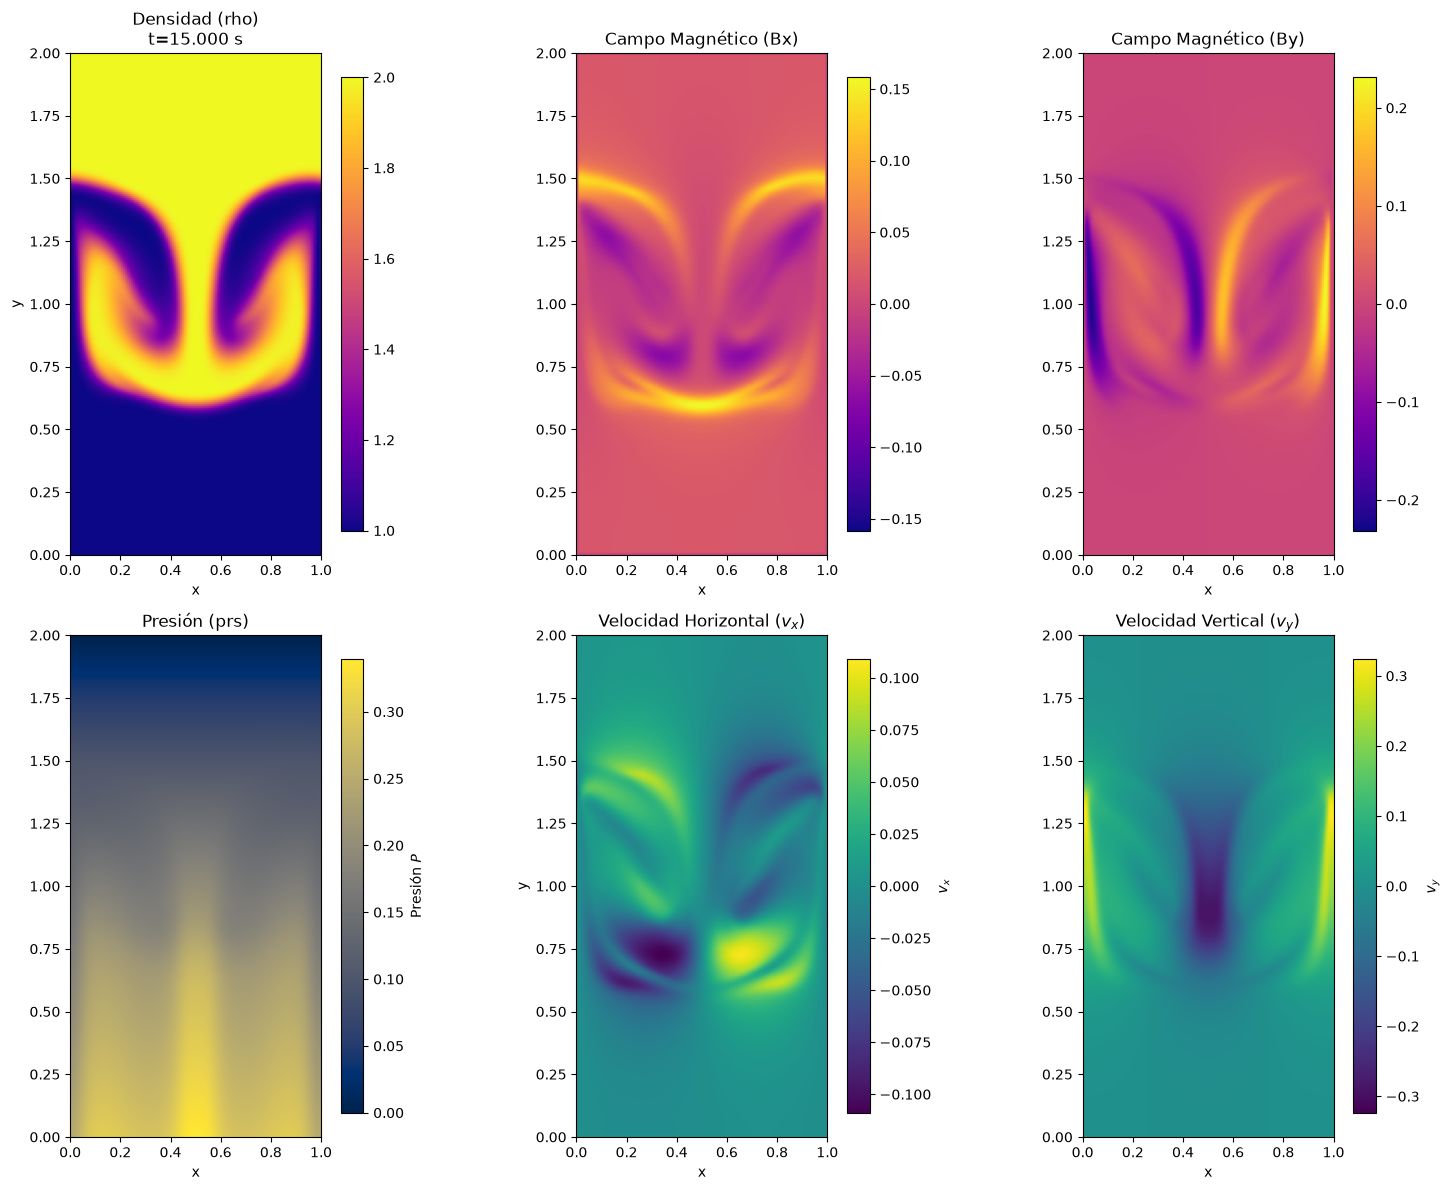

In [3]:

#VISUALIZACIÓN

print("Generando gráficos de 6 paneles...")


fig, axes = plt.subplots(2, 3, figsize=(16, 12))
ax1, ax2, ax3, ax4, ax5, ax6 = axes.flatten()


extension = [0, Nx * dx, 0, Ny * dy]

#Densidad (rho)
im1 = ax1.imshow(rho, cmap='plasma', origin='lower', extent=extension)
ax1.set_title(f"Densidad (rho)\nt={pasos*dt:.3f} s")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

#Componente X del Campo Magnético (Bx)

max_bx = np.max(np.abs(Bx)) if np.max(np.abs(Bx)) > 1e-6 else 1e-6
im2 = ax2.imshow(Bx, cmap='plasma', origin='lower', extent=extension, 
                 vmin=-max_bx, vmax=max_bx)
ax2.set_title("Campo Magnético (Bx)")
ax2.set_xlabel("x")
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

#Componente Y del Campo Magnético (By)

max_by = np.max(np.abs(By)) if np.max(np.abs(By)) > 1e-6 else 1e-6
im3 = ax3.imshow(By, cmap='plasma', origin='lower', extent=extension, 
                 vmin=-max_by, vmax=max_by)
ax3.set_title("Campo Magnético (By)")
ax3.set_xlabel("x")
fig.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)

#Presion
im4 = ax4.imshow(prs, cmap='cividis', origin='lower', extent=extension)
ax4.set_title("Presión (prs)")
ax4.set_xlabel("x")
fig.colorbar(im4, ax=ax4, fraction=0.046, pad=0.04).set_label(r'Presión $P$')

#Velocidad Horizontal (vx o u)
max_u = np.max(np.abs(u)) if np.max(np.abs(u)) > 1e-6 else 1e-6
im5 = ax5.imshow(u, cmap='viridis', origin='lower', extent=extension, 
                 vmin=-max_u, vmax=max_u)
ax5.set_title(r"Velocidad Horizontal ($v_x$)")
ax5.set_xlabel("x")
ax5.set_ylabel("y") # Solo el primer panel de la fila inferior lleva la "y"
fig.colorbar(im5, ax=ax5, fraction=0.046, pad=0.04).set_label(r'$v_x$')


#Velocidad Vertical (vy o v)

max_v = np.max(np.abs(v)) if np.max(np.abs(v)) > 1e-6 else 1e-6
im6 = ax6.imshow(v, cmap='viridis', origin='lower', extent=extension, 
                 vmin=-max_v, vmax=max_v)
ax6.set_title(r"Velocidad Vertical ($v_y$)")
ax6.set_xlabel("x")
fig.colorbar(im6, ax=ax6, fraction=0.046, pad=0.04).set_label(r'$v_y$')

plt.tight_layout()
plt.show()

## Comparacion y manejo de errores

### Divergencia Cuantitativa
Si bien el comportamiento global es correcto, las métricas de error absoluto (normas $L_1$ y $L_2$) demuestran que los campos escalares y vectoriales no coinciden de manera exacta 1:1 con PLUTO. Esto no representa una falla en la programación, sino que es la consecuencia natural de dos decisiones metodológicas de diseño:

1. **La Suposición de Incompresibilidad:** Como se discutió anteriormente, PLUTO es un código compresible que resuelve la Ecuación de Estado térmica, permitiendo que la densidad fluctúe por ondas de choque o efectos acústicos. Nuestro código en Python fuerza artificialmente la divergencia nula ($\nabla \cdot \vec{v} = 0$), filtrando todos estos efectos termodinámicos y produciendo un campo de presión y densidad inherentemente distinto en los detalles finos.
2. **Difusión Numérica del Esquema Upwind:** PLUTO utiliza Riemann Solvers de alta resolución (como Roe o HLL) con limitadores de pendiente que mantienen las interfaces entre fluidos extremadamente nítidas. En contraste, nuestro esquema de advección *Upwind* de primer orden inyecta una cantidad conocida de viscosidad artificial. Esta viscosidad numérica difumina ligeramente los bordes de los hongos, lo cual se traduce matemáticamente como un error elevado (especialmente en la variable $\rho$) al restar nuestra matriz con la matriz de bordes nítidos de PLUTO.
3. **El Comportamiento Engañoso del CFL (Paso de tiempo fijo vs Adaptativo):**
En nuestro código establecimos un paso de tiempo fijo ($\Delta t$). Esto hizo que la métrica de estabilidad CFL ($C = v \frac{\Delta t}{\Delta x}$) resultara engañosa. Al inicio, las velocidades son minúsculas (solo existe la perturbación semilla), por lo que el CFL es cercano a cero. Sin embargo, a mitad de la simulación, la gravedad acelera brutalmente las plumas en caída libre; las velocidades locales ($v$) se disparan y el número CFL local aumenta drásticamente.
A diferencia de PLUTO, que utiliza un **paso de tiempo adaptativo** (recalculando y reduciendo $\Delta t$ conforme el fluido acelera para mantener un CFL óptimo), nuestro código mantuvo el mismo $\Delta t$. Esto provocó que la difusión artificial ($\nu_{num} \propto v(1-C)$) y los errores de truncamiento fluctuaran violentamente durante la fase no lineal del hongo, disparando las discrepancias hacia el final del cálculo.

In [4]:
#Calcular el número CFL local en cada celda
CFL_x = (np.abs(u) * dt) / dx
CFL_y = (np.abs(v) * dt) / dy

cfl_max = max(np.max(CFL_x), np.max(CFL_y))
print(f"CFL Máximo alcanzado:{cfl_max:.6f}")

#Definir dimensiones de la malla
Nx = 128 
Ny = 256  
N_total = Nx * Ny

#Leer los datos binarios crudos de PLUTO
datos_crudos = np.fromfile('data.0001.dbl', dtype=np.float64)

# Extraer y redimensionar directamente a 2D (Ny, Nx)
rho_pluto = datos_crudos[0 : N_total].reshape((Ny, Nx))
u_pluto   = datos_crudos[N_total : 2 * N_total].reshape((Ny, Nx))
v_pluto   = datos_crudos[2 * N_total : 3 * N_total].reshape((Ny, Nx))
Bx_pluto  = datos_crudos[3 * N_total : 4 * N_total].reshape((Ny, Nx))
By_pluto  = datos_crudos[4 * N_total : 5 * N_total].reshape((Ny, Nx))
prs_pluto = datos_crudos[5 * N_total : 6 * N_total].reshape((Ny, Nx))

# Normalizar la presión para comparar Python incompresible vs PLUTO compresible
prs_py_norm = prs - np.mean(prs)
prs_pluto_norm = prs_pluto - np.mean(prs_pluto)

# Empaquetar las variables en un diccionario para automatizar el cálculo
variables = {
    'Densidad (rho)': (rho, rho_pluto),
    'Velocidad Horiz (u)': (u, u_pluto),
    'Velocidad Vert (v)': (v, v_pluto),
    'Campo Mag X (Bx)': (Bx, Bx_pluto),
    'Campo Mag Y (By)': (By, By_pluto),
    'Presion Norm (prs)': (prs_py_norm, prs_pluto_norm)
}

#Calcular e imprimir L1 y L2 para cada variable
print("="*45)
print("REPORTE DE ERRORES (PYTHON VS PLUTO)")
print("="*45)

for nombre, (var_py, var_pluto) in variables.items():
    error_absoluto = np.abs(var_py - var_pluto)
    norma_L1 = np.sum(error_absoluto) / N_total
    norma_L2 = np.sqrt(np.sum((var_py - var_pluto)**2) / N_total)
    
    print(f"{nombre:20s} | L1: {norma_L1:.4f}  |  L2: {norma_L2:.4f}")

print("="*45)

CFL Máximo alcanzado:0.206976
REPORTE DE ERRORES (PYTHON VS PLUTO)
Densidad (rho)       | L1: 0.2700  |  L2: 0.4528
Velocidad Horiz (u)  | L1: 0.0212  |  L2: 0.0316
Velocidad Vert (v)   | L1: 0.0361  |  L2: 0.0556
Campo Mag X (Bx)     | L1: 0.0257  |  L2: 0.0350
Campo Mag Y (By)     | L1: 0.0374  |  L2: 0.0557
Presion Norm (prs)   | L1: 0.0838  |  L2: 0.0979


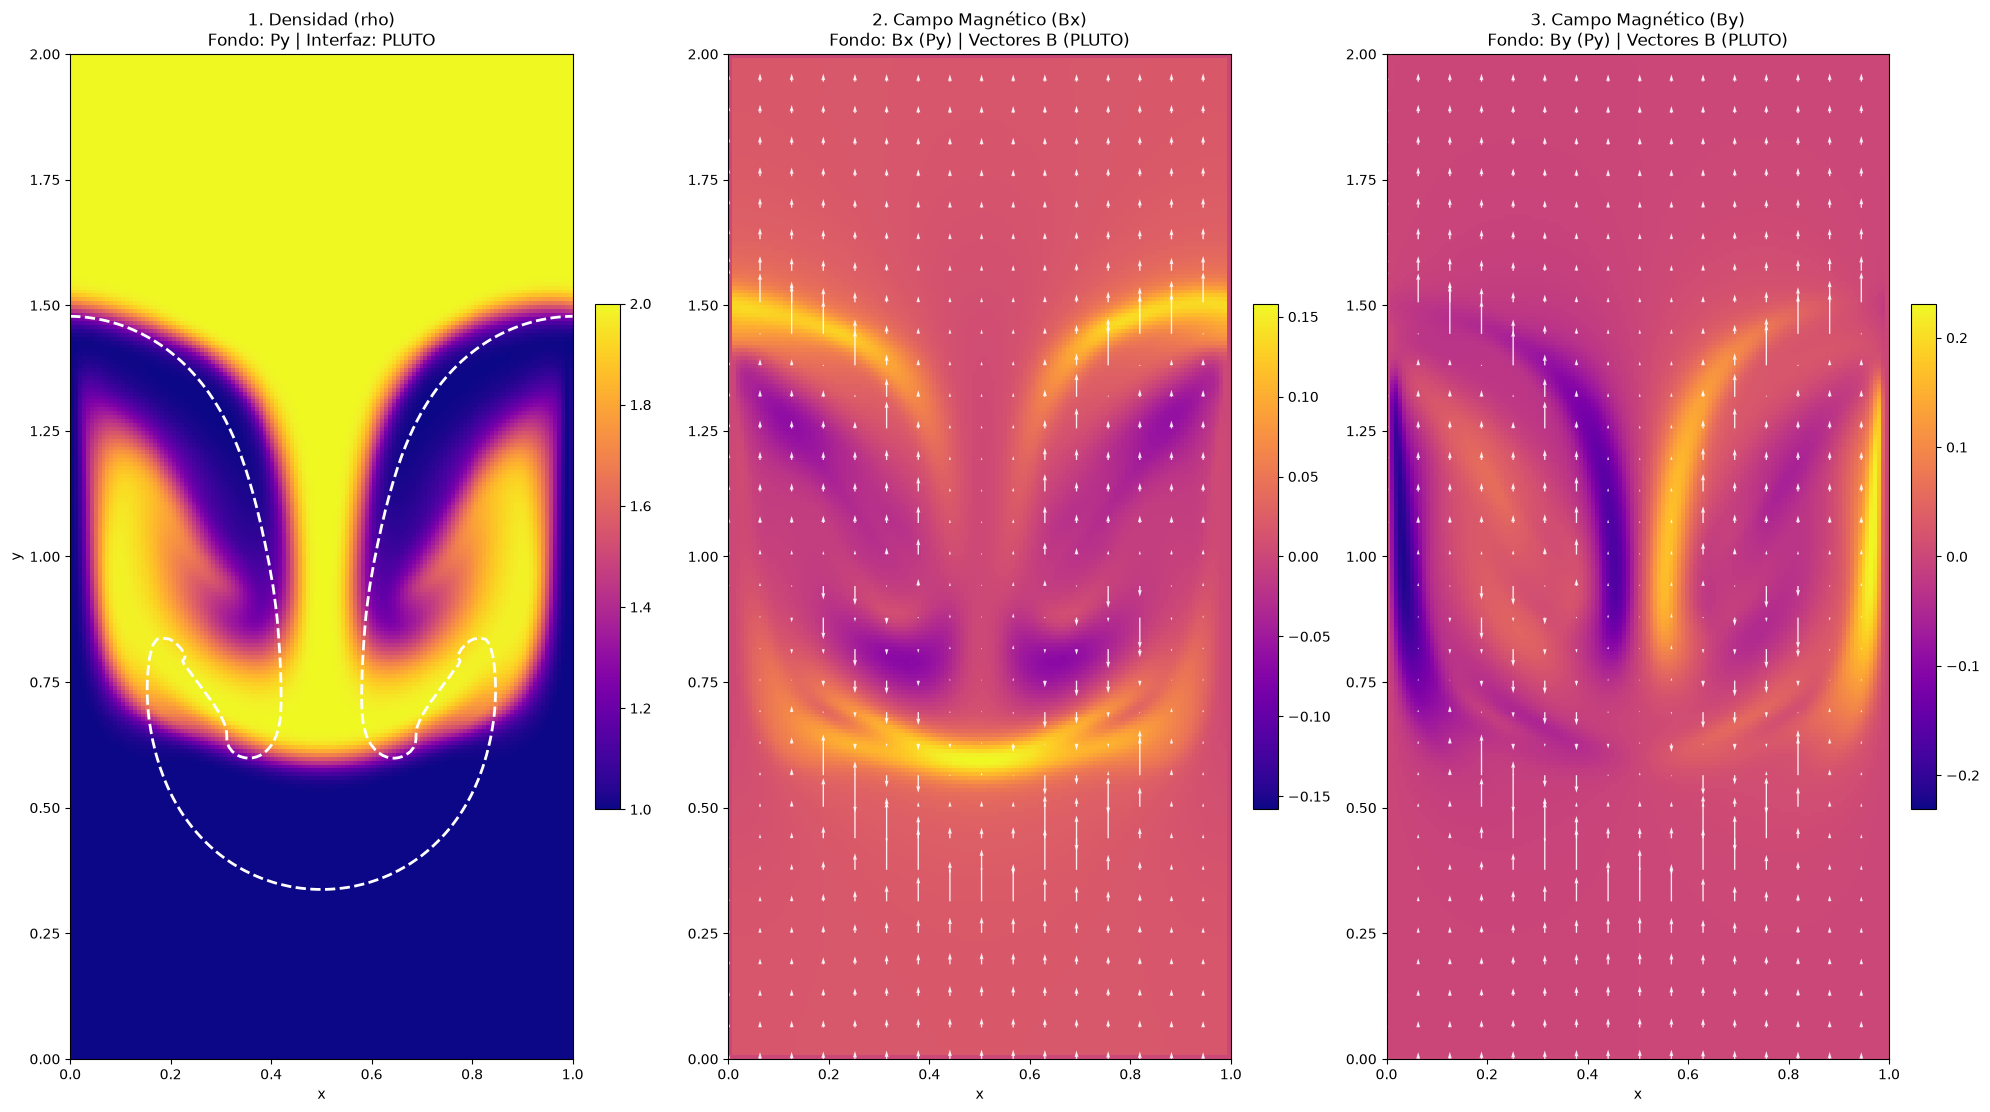

In [13]:
Lx = Nx * dx
Ly = Ny * dy
extension = [0, Lx, 0, Ly]

X_line = np.linspace(0, Lx, Nx)
Y_line = np.linspace(0, Ly, Ny)
X_grid, Y_grid = np.meshgrid(X_line, Y_line)

#Crear figura de 2 filas y 3 columnas
fig, axes = plt.subplots(1, 3, figsize=(20, 15))
ax1, ax2, ax3= axes.flatten()

# Definimos el salto global para todas las flechas (quiver)
salto = 8 


#Densidad (Overlay de Contorno de Interfaz)
im1 = ax1.imshow(rho, cmap='plasma', origin='lower', extent=extension)
ax1.contour(rho_pluto, levels=[1.5], colors='white', linewidths=2, linestyles='dashed', extent=extension)
ax1.set_title(f"1. Densidad (rho)\nFondo: Py | Interfaz: PLUTO")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

#Bx (Overlay de Vectores Magnéticos)
max_bx = np.max(np.abs(Bx)) if np.max(np.abs(Bx)) > 1e-6 else 1e-6
im2 = ax2.imshow(Bx, cmap='plasma', origin='lower', extent=extension, vmin=-max_bx, vmax=max_bx)
ax2.quiver(X_grid[::salto, ::salto], Y_grid[::salto, ::salto], 
           Bx_pluto[::salto, ::salto], By_pluto[::salto, ::salto], 
           color='white', scale=1.2, alpha=0.9) 
ax2.set_title("2. Campo Magnético (Bx)\nFondo: Bx (Py) | Vectores B (PLUTO)")
ax2.set_xlabel("x")
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)


#By (Overlay de Vectores Magnéticos)
max_by = np.max(np.abs(By)) if np.max(np.abs(By)) > 1e-6 else 1e-6
im3 = ax3.imshow(By, cmap='plasma', origin='lower', extent=extension, vmin=-max_by, vmax=max_by)

ax3.quiver(X_grid[::salto, ::salto], Y_grid[::salto, ::salto], 
           Bx_pluto[::salto, ::salto], By_pluto[::salto, ::salto], 
           color='white', scale=1.2, alpha=0.9)
ax3.set_title("3. Campo Magnético (By)\nFondo: By (Py) | Vectores B (PLUTO)")
ax3.set_xlabel("x")
fig.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

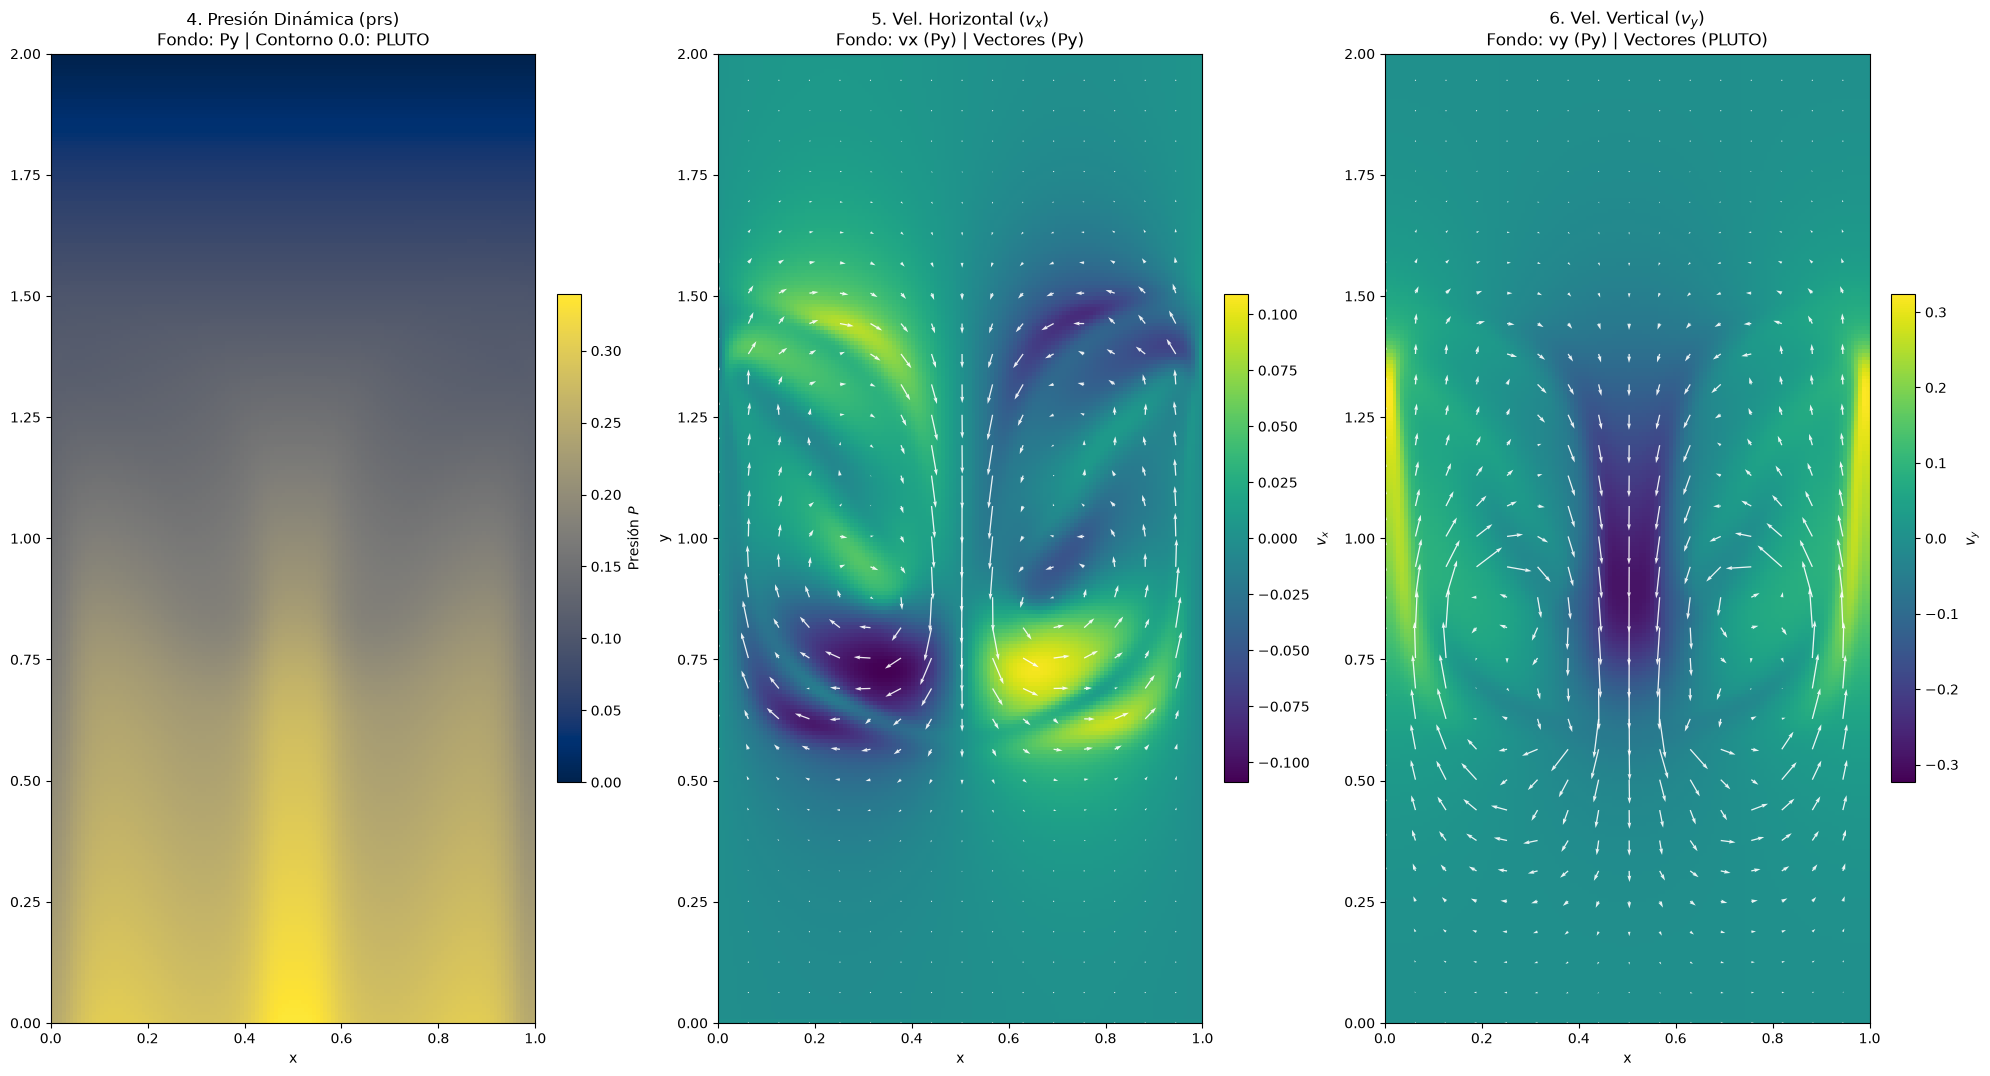

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(20, 15))
ax4, ax5, ax6 = axes.flatten()

#Presión

im4 = ax4.imshow(prs, cmap='cividis', origin='lower', extent=extension)
ax4.set_title("4. Presión Dinámica (prs)\nFondo: Py | Contorno 0.0: PLUTO")
ax4.set_xlabel("x")
fig.colorbar(im4, ax=ax4, fraction=0.046, pad=0.04).set_label(r'Presión $P$')


# PANEL 5: Velocidad Horizontal (Overlay de Vectores)

max_u = np.max(np.abs(u)) if np.max(np.abs(u)) > 1e-6 else 1e-6
im5 = ax5.imshow(u, cmap='viridis', origin='lower', extent=extension, vmin=-max_u, vmax=max_u)
ax5.quiver(X_grid[::salto, ::salto], Y_grid[::salto, ::salto], 
           u_pluto[::salto, ::salto], v_pluto[::salto, ::salto], 
           color='white', scale=3, alpha=0.9)
ax5.set_title(r"5. Vel. Horizontal ($v_x$)" + "\nFondo: vx (Py) | Vectores (PLUTO)")
ax5.set_xlabel("x")
ax5.set_ylabel("y") 
fig.colorbar(im5, ax=ax5, fraction=0.046, pad=0.04).set_label(r'$v_x$')


# PANEL 6: Velocidad Vertical (Overlay de Vectores)

max_v = np.max(np.abs(v)) if np.max(np.abs(v)) > 1e-6 else 1e-6
im6 = ax6.imshow(v, cmap='viridis', origin='lower', extent=extension, vmin=-max_v, vmax=max_v)
ax6.quiver(X_grid[::salto, ::salto], Y_grid[::salto, ::salto], 
           u_pluto[::salto, ::salto], v_pluto[::salto, ::salto], 
           color='white', scale=3, alpha=0.9)
ax6.set_title(r"6. Vel. Vertical ($v_y$)" + "\nFondo: vy (Py) | Vectores (PLUTO)")
ax6.set_xlabel("x")
fig.colorbar(im6, ax=ax6, fraction=0.046, pad=0.04).set_label(r'$v_y$')

plt.tight_layout()
plt.show()

## Conclusiones

El desarrollo de este proyecto nos ha permitido integrar los fundamentos teóricos de la Magnetohidrodinámica (MHD) con el cálculo numérico, logrando simular y analizar con éxito la inestabilidad de Rayleigh-Taylor (RTI). A partir de los resultados obtenidos y la comparación con el código profesional PLUTO, concluimos lo siguiente:

1. **Validación del Solver Propio:** La formulación de Función de Corriente - Vorticidad ($\psi - \omega$) demostró ser una estrategia robusta para garantizar la incompresibilidad del fluido ($\nabla \cdot \vec{v} = 0$). Los mapas de densidad y los campos de velocidad de nuestro código en Python reproducen fielmente la macroestructura del "hongo" característico de la inestabilidad, validando nuestro diseño metodológico frente a un estándar de la industria como PLUTO.
2. **Dinámica Física (Gravedad vs. Magnetismo):** La simulación evidenció claramente la competencia de fuerzas dictada por la relación de dispersión lineal. El gradiente baroclínico impulsó el crecimiento de los vórtices debido a la diferencia de densidades, mientras que la tensión magnética (consecuencia de la Ley de Faraday y la fuerza de Lorentz) actuó como un mecanismo estabilizador que se opone a la deformación excesiva de las líneas de campo horizontal.
3. **Disipación y Esquemas Numéricos:** Al superponer los contornos y vectores, observamos ligeras diferencias en las zonas de mayor gradiente. Esto corrobora el impacto de los esquemas de discretización: mientras que nuestro código emplea un esquema *Upwind* de primer orden que introduce cierta difusión numérica (suavizando la interfaz), PLUTO utiliza *Riemann solvers* de alta resolución (tipo Godunov) que capturan los choques y discontinuidades con mayor nitidez.
4. **Perspectivas a Futuro:** Este modelo base sirve como punto de partida para implementaciones más complejas. Las mejoras futuras podrían incluir la transición a esquemas de advección de orden superior (como WENO o TVD), la extensión a 3 dimensiones, o el acoplamiento de la ecuación de energía para estudiar el régimen MHD compresible.

En resumen, la construcción de este código no solo reproduce un fenómeno astrofísico y de plasma fundamental, sino que consolida la comprensión de los retos inherentes a la Dinámica de Fluidos Computacional (CFD).